# LeafContourEFD — PCA of *Triadica sebifera* leaf contours (orientation-normalized elliptic Fourier analysis)

Reproduction of one analysis from: **"LeafContourEFD: a reproducible workflow for
elliptic Fourier analysis with orientation normalization and lateral asymmetry"**
(bioRxiv v1, posted 2026-04-20; DOI [10.64898/2026.04.16.718881](https://doi.org/10.64898/2026.04.16.718881); CC-BY 4.0 preprint).

**This notebook executes a partial demonstration**: the author's own R analysis
([maple60/leaf-contour-efd-analysis @ `94a9995`](https://github.com/maple60/leaf-contour-efd-analysis)),
run unmodified on the 30 *Triadica sebifera* contours from the author's Dryad dataset
([doi:10.5061/dryad.6t1g1jxdh](https://doi.org/10.5061/dryad.6t1g1jxdh), version 438792, CC0):

1. Overlay preview of the 30 original contour CSVs.
2. Contour-check figure: original contour vs reconstruction from the author's published
   oriented-true-normalized EFD coefficients (the author's `contour_check` notebook).
3. The three PCAs from the author's `pca_triadica_sebifera` notebook:
   conventional normalized EFD, true EFD normalization, oriented true EFD normalization (nb_h = 5).
4. Sensitivity of PC1 shares to the number of harmonics (nb_h = 5 vs 10; the preprint text
   reports 10 harmonics and PC1 ≈ 46.7 / 55.0 / 74.0 % for the three methods).

**Execution status**: CPU Colab runtime (no GPU needed — pure R statistical computation).
The Python cells are only a launcher/orchestrator; all scientific computation is the
authors' unmodified R code executed by `Rscript`, plus small plotting-device wrappers
(PNG instead of the authors' SVG; documented below).

**日本語の概要**: このノートブックは、*Triadica sebifera*（セバイオウシュウ）30 標本の輪郭
データ（Dryad, CC0）を用いて、著者自身の R 解析コードをそのまま実行します。
(1) 原輪郭のオーバーレイプレビュー、(2) 公表済み正規化 EFD 係数からの再構成輪郭と原輪郭の
重ね合わせ図、(3) 3 種類の正規化法（従来法・true 正規化・方向付き true 正規化）による PCA、
(4) 調和数 nb_h = 5 / 10 の感度分析。GPU は不要で、CPU ランタイムで実行します。
科学計算はすべて R（Rscript）で行われ、Python は起動・表示のみ担います。

## Runtime selection / ランタイム選択

- **Select: Runtime → Change runtime type → CPU** (the default is fine). No GPU is used:
  the analysis is small statistical computation on 30 CSV contours.
- Expected wall time in a fresh runtime: **≈ 30–40 min total**, dominated by the one-time
  installation of R packages (≈ 26 min measured on a fresh 2026-11 Colab CPU VM, which
  already ships R 4.6.1). Data download is a few MB via HTTP range requests (fallback:
  the full 1.6 GB `data.zip`, only if range reads fail). The analysis itself runs in
  under a minute.
- **Run all**: ランタイム → すべてのセルを実行. All downloads (R packages, Dryad data)
  happen inside this notebook; nothing is needed from your local machine.
- 制限: 筆者のノートブックでは図を SVG 保存していますが、本ノートブックは PNG 保存に変更した
  だけの外観上の違いがあります。科学計算そのものは筆者コードを改変していません。

### Check the environment / 環境の確認

Check the Python version and whether `Rscript` is already available on the Colab VM,
and create the working directories used by later cells (`%%writefile` cannot create
missing parent directories). **日本語**: Python と R の有無を確認し、後続のセルで使う
作業ディレクトリを作成します。

In [ ]:
import shutil, subprocess, sys, pathlib

for d in ["/content/leaf/setup", "/content/leaf/R", "/content/leaf/zip_content",
          "/content/leaf/inputs/contours", "/content/leaf/inputs/coefficients",
          "/content/out"]:
    pathlib.Path(d).mkdir(parents=True, exist_ok=True)
print("Python:", sys.version.split()[0])
print("Rscript on PATH:", shutil.which("Rscript"))

Python: 3.13.18
Rscript on PATH: /usr/bin/Rscript


### Install R (if absent) / R のインストール

Installs `r-base` from the Ubuntu archive plus the system libraries required by the
binary builds of the R packages used by Momocs (`sf` needs GDAL/PROJ/UDUNITS system
libraries even when installed as a prebuilt binary). This takes a few minutes and
streams its output. **日本語**: R 本体と、R パッケージ（`sf` など）が動くために必要な
システムライブラリを apt でインストールします（数分）。既に R がある場合はスキップします。

In [ ]:
import shutil, subprocess

if shutil.which("Rscript") is None:
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(
        ["apt-get", "install", "-y", "r-base",
         "libgdal32", "libproj25", "libudunits2-0", "libgeos-c1v5"],
        check=True,
    )
else:
    print("R already present; skipping apt install.")
print(subprocess.run(["Rscript", "-e", "cat(R.version.string)"],
                     capture_output=True, text=True).stdout)

R already present; skipping apt install.


R version 4.6.1 (2026-06-24)


### Write the R package installation script / R パッケージ導入スクリプトの作成

`Momocs` (the author's morphometrics library) was **removed from CRAN on 2026-03-18**,
so the notebook installs the pinned source tarball `Momocs_1.5.0` from the CRAN Archive.
All packages listed in Momocs 1.5.0 `Imports` must be present at install time; they are
installed as prebuilt binaries or source builds from the Posit Package Manager Ubuntu
repository. Measured on a fresh Colab CPU VM (2026-11-16): **≈ 26 min**.
**日本語**: Momocs は 2026-03-18 に CRAN から削除されたため、CRAN Archive
のピン留めされた 1.5.0 ソースをインストールします。依存パッケージは Posit Package
Manager のリポジトリから導入します（新規 CPU VM で実測約 26 分）。

In [ ]:
%%writefile /content/leaf/setup/install_r.R
options(warn = 1)
pkgs <- c("cluster", "dendextend", "dplyr", "magrittr", "geometry", "geomorph",
          "ggplot2", "jpeg", "MASS", "progress", "RColorBrewer", "sp", "sf",
          "vegan", "tibble")
repo <- "https://packagemanager.posit.co/cran/__linux__/jammy/latest"
install.packages(pkgs, repos = repo, Ncpus = 2)
# Momocs was removed from CRAN on 2026-03-18 -> pinned 1.5.0 source from CRAN Archive.
# (NeedsCompilation: no, pure R; verified from the tarball DESCRIPTION.)
download.file(
  "https://cran.r-project.org/src/contrib/Archive/Momocs/Momocs_1.5.0.tar.gz",
  "/content/Momocs_1.5.0.tar.gz"
)
install.packages("/content/Momocs_1.5.0.tar.gz", repos = NULL, type = "source")

Writing /content/leaf/setup/install_r.R


### Run the R package installation / インストールの実行

Runs the script written above with `Rscript`. The output is streamed so that any
failed package is visible (≈ 26 min measured). **日本語**: 上で書いたスクリプトを `Rscript` で
実行します。出力をそのまま表示するので、失敗したパッケージがあればすぐ分かります。

In [ ]:
import subprocess

pathlib.Path("/content/leaf/setup").mkdir(parents=True, exist_ok=True)
r = subprocess.run(["Rscript", "/content/leaf/setup/install_r.R"], timeout=2400)
print("install_r.R exit code:", r.returncode)

install_r.R exit code: 0


### Verify the R setup / R セットアップの検証

`library(Momocs)` is the hard requirement of the author's code; this cell fails loudly
if any dependency is unusable. **日本語**: 著者コードの必須要件 `library(Momocs)` を確認します。
依存関係に問題があれば、ここで明示的にエラーになります。

In [ ]:
r = subprocess.run(
    ["Rscript", "-e",
     'library(Momocs); cat(R.version.string, "| Momocs", as.character(packageVersion("Momocs")), "\n")'],
    capture_output=True, text=True,
)
print(r.stdout, r.stderr)
assert r.returncode == 0, "Momocs failed to load; inspect the install cell output above."

R version 4.6.1 (2026-06-24) | Momocs 1.5.0 
 
Attaching package: ‘Momocs’

The following object is masked from ‘package:stats’:

    filter




### Verify the Dryad file metadata / Dryad ファイルメタデータの検証

The input data come from Dryad **doi:10.5061/dryad.6t1g1jxdh** (CC0), version **438792**,
file `data.zip` (1,617,538,849 bytes, SHA-256 `09ee8857…f16e9450a`). This cell queries
the documented public Dryad API (`GET /api/v2/versions/438792/files`) and cross-checks
the recorded size and digest. **日本語**: Dryad の公開 API でバージョン 438792 の
`data.zip` の記録済みサイズと SHA-256 を取得・照合します。

In [ ]:
import json, urllib.request

FILES_API = "https://datadryad.org/api/v2/versions/438792/files"
EXPECTED = {
    "path": "data.zip",
    "size": 1617538849,
    "sha256": "09ee8857b22b711f2cde74dd716e48ec5370532eff4880118f31740f16e9450a",
}
with urllib.request.urlopen(FILES_API, timeout=60) as resp:
    listing = json.load(resp)
entry = next(f for f in listing["_embedded"]["stash:files"] if f["path"] == "data.zip")
assert entry["size"] == EXPECTED["size"], (entry["size"], EXPECTED["size"])
assert entry["digest"].lower() == EXPECTED["sha256"], entry["digest"]
print("data.zip verified against Dryad metadata (size + sha-256).")

data.zip verified against Dryad metadata (size + sha-256).


### Resolve a downloadable URL / ダウンロード URL の解決

Dryad's file-level API download now requires an API token (verified: HTTP 401
"must have current bearer token" from Colab), and the version-level download endpoint
rejects this 1.6 GB dataset (HTTP 405). The website's own download-info endpoint
(`downloads/zip_assembly_info/<version>`) still serves a presigned S3 URL for each file
publicly; this cell resolves it and cross-checks the size. **日本語**: Dryad のファイル単位
API ダウンロードは現在トークン必須（401）、バージョン単位ダウンロードはこのサイズでは
不可（405）のため、Dryad ウェブサイト自身のダウンロード情報エンドポイントから S3 署名付き
URL を取得します（サイズを照合）。

In [ ]:
import requests

UA = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) leaf-contour-efd-repro/1.0"}
resp = requests.get("https://datadryad.org/downloads/zip_assembly_info/438792",
                    headers=UA, timeout=60)
resp.raise_for_status()
entries = resp.json()
entry = next(e for e in entries if e.get("filename") == "data.zip")
assert entry["size"] == EXPECTED["size"], entry
s3_url = entry["url"]
print("resolved presigned S3 host:", s3_url.split("/")[2])

resolved presigned S3 host: dryad-assetstore-merritt-west.s3.us-west-2.amazonaws.com


### Extract only the needed members via HTTP range requests / 必要なメンバーだけを取得

The archive holds 8,176 members across many species directories, but this scope needs
only `data/contour_triadica_sebifera/*.csv` (30 contours) and
`data/coefficients_efd_normalized_triadica_sebifera/*.csv` (30 coefficient files).
`remotezip` reads the ZIP central directory over HTTP and fetches only the selected
members via range requests against the S3 URL (a few MB instead of 1.6 GB). Each member
is CRC-checked by `zipfile` on extraction, and files are normalized into flat
`/content/leaf/inputs/` directories. **日本語**: `remotezip` で ZIP のセントラルディレクトリを
HTTP Range リクエストで読み、必要な 60 個の CSV だけを数 MB で取得します（CRC チェック付き）。
レンジ読み取りに失敗した場合は、次のセルが 1.6 GB の全体ダウンロードにフォールバックします。

In [ ]:
%pip install -q remotezip

import glob, re, zipfile
from pathlib import Path
from remotezip import RemoteZip

INPUTS = Path("/content/leaf/inputs")
CONTENTS_DIR = Path("/content/leaf/zip_content")
CONTENTS_DIR.mkdir(parents=True, exist_ok=True)
PATTERNS = [
    r"(^|/)data/contour_triadica_sebifera/[^/]+\.csv$",
    r"(^|/)data/coefficients_efd_normalized_triadica_sebifera/[^/]+\.csv$",
]

def normalize_extracted():
    """Copy the extracted contour/coefficient CSVs into flat canonical dirs."""
    for sub, dest in [("contour_triadica_sebifera", "contours"),
                      ("coefficients_efd_normalized_triadica_sebifera", "coefficients")]:
        (INPUTS / dest).mkdir(parents=True, exist_ok=True)
        found = glob.glob(str(CONTENTS_DIR / "**" / sub / "*.csv"), recursive=True)
        bases = [Path(f).name for f in found]
        assert len(bases) == len(set(bases)), f"basename collision in {sub}"
        for f in found:
            (INPUTS / dest / Path(f).name).write_bytes(Path(f).read_bytes())
        print(f"{sub}: {len(found)} files")

with RemoteZip(s3_url) as z:
    names = z.namelist()
    selected = [n for n in names if any(re.search(p, n) for p in PATTERNS)]
    print(f"zip members: {len(names)}; selected: {len(selected)}")
    assert len(selected) == 60, f"expected 60 members, got {len(selected)}: {selected[:5]}"
    for n in selected:
        z.extract(n, path=str(CONTENTS_DIR))  # extract() CRC-checks while streaming
normalize_extracted()

zip members: 8176; selected: 60


contour_triadica_sebifera: 30 files
coefficients_efd_normalized_triadica_sebifera: 30 files


### Fallback: full `data.zip` download / フォールバック: 全体ダウンロード

Only runs if the ranged extraction above failed or produced incomplete data. Downloads
the full 1.6 GB archive from the resolved S3 URL, verifies its SHA-256 against the
Dryad-recorded digest, and extracts the same 60 members (each CRC-checked).
**日本語**: レンジ読み取りが失敗した場合のみ実行されます。1.6 GB 全体をダウンロードし
SHA-256 を検証してから、同じ 60 個の CSV を展開します。

In [ ]:
import hashlib

def inputs_ok():
    return (len(glob.glob(str(INPUTS / "contours" / "*.csv"))) == 30
            and len(glob.glob(str(INPUTS / "coefficients" / "*.csv"))) == 30)

if not inputs_ok():
    print("Ranged extraction incomplete; falling back to the full 1.6 GB download.")
    archive = Path("/content/data.zip")
    h = hashlib.sha256()
    with requests.get(s3_url, stream=True, timeout=120, headers=UA) as resp:
        resp.raise_for_status()
        with open(archive, "wb") as out:
            for chunk in resp.iter_content(1 << 20):
                out.write(chunk)
                h.update(chunk)
    assert h.hexdigest() == EXPECTED["sha256"], "sha-256 mismatch on full download"
    with zipfile.ZipFile(archive) as z:
        names = z.namelist()
        selected = [n for n in names if any(re.search(p, n) for p in PATTERNS)]
        assert len(selected) == 60, selected
        z.extractall(str(CONTENTS_DIR), members=selected)
        for n in selected:
            z.read(n)  # CRC check
    normalize_extracted()
    print("full download verified and extracted")
else:
    print("ranged extraction already complete; skipping fallback")

ranged extraction already complete; skipping fallback


### Validate the extracted inputs / 入力データの検証

The author's `contour_check` notebook states there are **30 samples**; the coefficient
files were produced by the LeafContourEFD GUI with columns `n, A0, C0, an, bn, cn, dn`.
This cell checks counts, columns, and coordinate ranges. **日本語**: 輪郭 30 ファイル・
係数 30 ファイルの数、列名、座標の範囲を検証します。

In [ ]:
import csv

contours = sorted(glob.glob(str(INPUTS / "contours" / "*.csv")))
coeffs = sorted(glob.glob(str(INPUTS / "coefficients" / "*.csv")))
assert len(contours) == 30, f"expected 30 contour CSVs, got {len(contours)}"
assert len(coeffs) == 30, f"expected 30 coefficient CSVs, got {len(coeffs)}"
with open(contours[0]) as f:
    rows = list(csv.reader(f))
header = rows[0]
assert {"x", "y"} <= set(header), header
xs = [float(r[0]) for r in rows[1:]]
ys = [float(r[1]) for r in rows[1:]]
print("30 contour CSVs, 30 coefficient CSVs")
print(f"first contour: {len(rows)-1} points, x range [{min(xs):.1f}, {max(xs):.1f}], "
      f"y range [{min(ys):.1f}, {max(ys):.1f}]")
with open(coeffs[0]) as f:
    print("coefficient columns:", next(csv.reader(f)))

30 contour CSVs, 30 coefficient CSVs
first contour: 1878 points, x range [592.0, 1337.0], y range [121.0, 791.0]
coefficient columns: ['n', 'A0', 'C0', 'an', 'bn', 'cn', 'dn']


### Fetch the author's R source files (pinned commit) / 著者の R ソース取得

Downloads the four R files used by the author's notebooks from the pinned commit
`94a9995` and verifies each file's **git blob SHA-1**, so any content drift fails
loudly. These are the authors' own functions, copied unmodified.
**日本語**: 著者の解析リポジトリ（ピン留めコミット）から R ファイル 4 つを取得し、
git blob SHA-1 で完全性を検証します。著者コードは無改変で使用します。

In [ ]:
import hashlib, urllib.request

COMMIT = "94a99954fefea7b42a2c37bc1174fdc2f1892c6b"
BASE_URL = "https://raw.githubusercontent.com/maple60/leaf-contour-efd-analysis/" + COMMIT
FILES = {
    "R/geometry.R": "84c5eadfbadb553744c0373cf240a97c2b18ef55",
    "R/normalization.R": "f2f3763b28b160301555ed7b89b13c810b65aec7",
    "R/compare_contours.R": "d269950d00cf2aa9b080c267dabfa27c6ef60144",
    "R/pca_plot.R": "32cece67029dc15948802376fb9ed9acb36e94e8",
}
R_DIR = pathlib.Path("/content/leaf/R")
R_DIR.mkdir(parents=True, exist_ok=True)

def blob_sha1(b: bytes) -> str:
    h = hashlib.sha1()
    h.update(f"blob {len(b)}\0".encode())
    h.update(b)
    return h.hexdigest()

for rel, expected in FILES.items():
    with urllib.request.urlopen(f"{BASE_URL}/{rel}", timeout=60) as resp:
        content = resp.read()
    got = blob_sha1(content)
    assert got == expected, f"{rel}: blob sha1 {got} != {expected}"
    (R_DIR / pathlib.Path(rel).name).write_bytes(content)
    print(f"verified {rel}  {got[:12]}... ({len(content)} B)")

verified R/geometry.R  84c5eadfbadb... (1852 B)
verified R/normalization.R  f2f3763b28b1... (7350 B)


verified R/compare_contours.R  d269950d00cf... (3536 B)
verified R/pca_plot.R  32cece67029d... (1077 B)


### Shared data-loading script / 共通のデータ読み込みスクリプト

Writes the authors' contour-loading code (from `contour_check_triadica_sebifera.qmd` /
`pca_triadica_sebifera.qmd`, commit `94a9995`) as a shared `load_data.R`: read each CSV,
keep `x`/`y`, close the contour by appending the first point if needed, and name the
list by sample ID — verbatim author logic, reading from the canonical input directory.
**日本語**: 著者の輪郭読み込みコード（CSV 読み込み、x/y 列の抽出、必要なら閉輪郭化、
標本 ID 付きリスト化）を共有スクリプト `load_data.R` として保存します。

In [ ]:
%%writefile /content/leaf/R/load_data.R
# Author loading code (pca_triadica_sebifera.qmd @ 94a9995), verbatim logic;
# only the data directory points to this notebook's canonical input dir.
file_paths_xy <- list.files(
  "/content/leaf/inputs/contours",
  full.names = TRUE,
  pattern = "\\.csv$"
)
id_name <- tools::file_path_sans_ext(basename(file_paths_xy))
xy_list <- lapply(file_paths_xy, function(fp) {
  df <- read.csv(fp)
  df <- df[, c("x", "y")]
  df <- as.matrix(df)
  storage.mode(df) <- "double"
  # Ensure the contour is closed: append the first point if needed.
  if (!all(df[1, ] == df[nrow(df), ])) {
    df <- rbind(df, df[1, ])
  }
  return(df)
})
names(xy_list) <- id_name
cat("loaded contours:", length(xy_list), "\n")

Writing /content/leaf/R/load_data.R


### Input preview: the 30 original contours / 入力プレビュー: 原輪郭 30 標本

Plots all 30 *Triadica sebifera* contours (centroid-centered, semi-transparent) after
loading them with the authors' own code. This is real input data — a human-readable
check before any analysis. **日本語**: 著者のコードで読み込んだ 30 標本の原輪郭を
（重心中心・半透明で）重ねて描画します。解析前に実データを確認するプレビューです。

In [ ]:
%%writefile /content/leaf/R/preview.R
suppressPackageStartupMessages(library(Momocs))
source("/content/leaf/R/load_data.R")

# Cosmetics only: PNG device (authors save SVG), 150 dpi.
png("/content/out/contour_preview.png", width = 1200, height = 1200, res = 150)
par(mar = c(4, 4, 2, 1))
allxy <- do.call(rbind, lapply(xy_list, function(xy) sweep(xy, 2, colMeans(xy), "-")))
xr <- range(allxy[, 1]); yr <- range(allxy[, 2])
pad <- 0.05 * max(diff(xr), diff(yr))
plot(NA, xlim = xr + c(-pad, pad), ylim = yr + c(-pad, pad), asp = 1,
     xlab = "x (px, centroid-centered)", ylab = "y (px, centroid-centered)",
     main = "Triadica sebifera: 30 original contours")
for (xy in xy_list) {
  centered <- sweep(xy, 2, colMeans(xy), "-")
  lines(centered, col = adjustcolor("steelblue", alpha.f = 0.35))
}
dev.off()
cat("saved /content/out/contour_preview.png\n")

Writing /content/leaf/R/preview.R


### Run the preview / プレビューの実行

Runs the preview script with `Rscript` and displays the saved PNG inline.
**日本語**: プレビュースクリプトを `Rscript` で実行し、保存した PNG を表示します。

loaded contours: 30 
null device 
          1 
saved /content/out/contour_preview.png




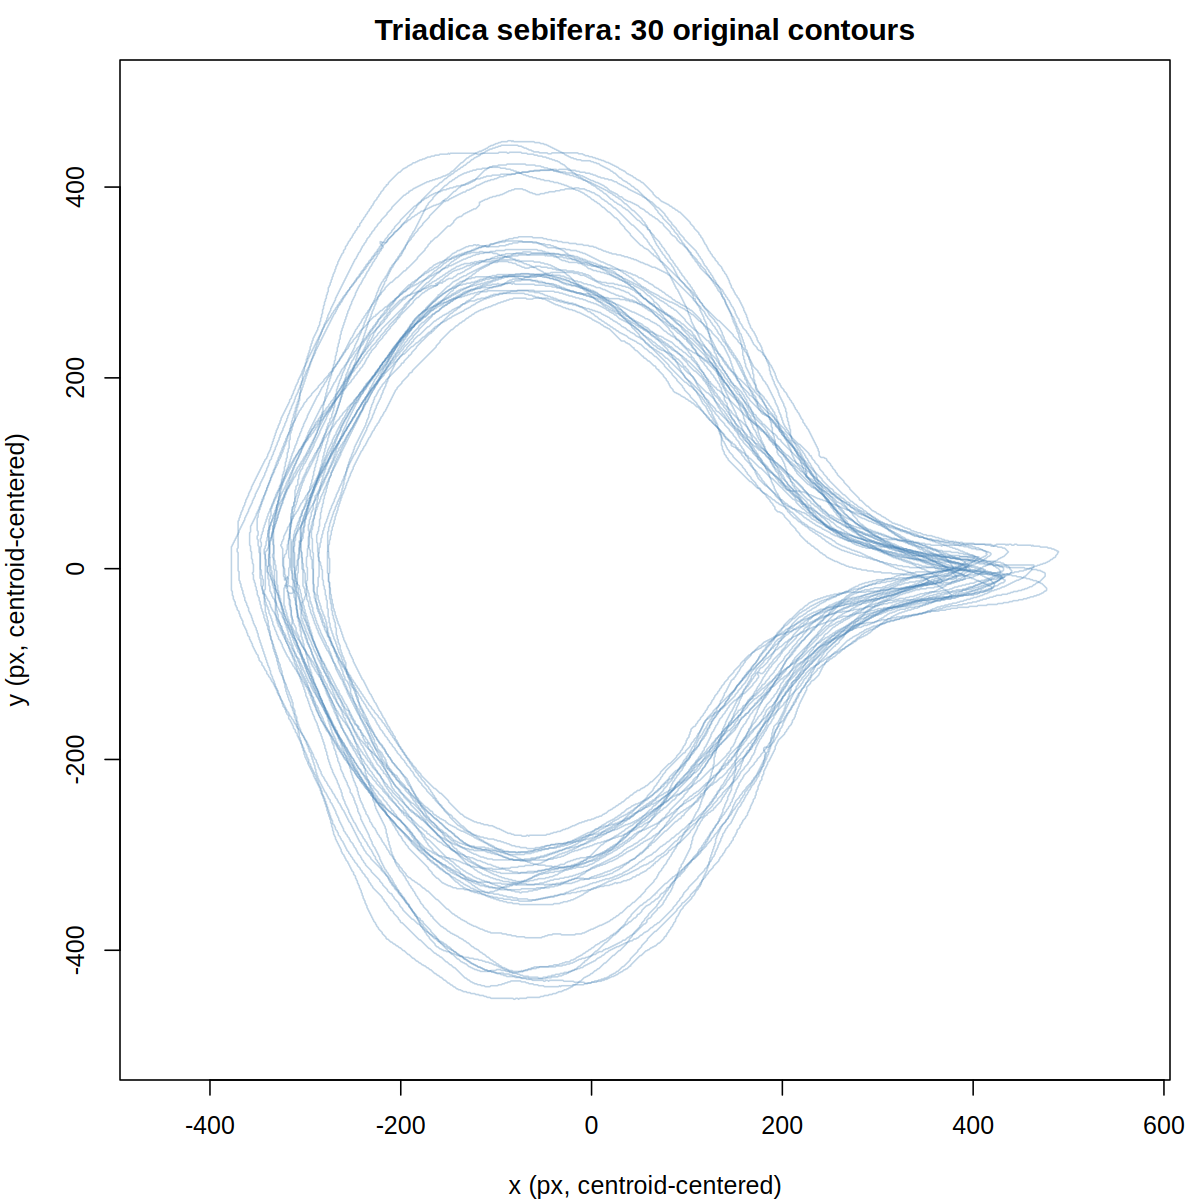

In [ ]:
import subprocess

pathlib.Path("/content/out").mkdir(parents=True, exist_ok=True)
r = subprocess.run(["Rscript", "/content/leaf/R/preview.R"],
                   capture_output=True, text=True, timeout=600)
print(r.stdout[-2000:]); print(r.stderr[-2000:])
assert r.returncode == 0, "preview.R failed"

from IPython.display import Image, display
display(Image(filename="/content/out/contour_preview.png"))

### Contour check: original vs reconstruction from published coefficients / 輪郭チェック図

Runs the author's `compare_contour_oriented_true_EFD_normalization()` (from
`R/compare_contours.R`, commit `94a9995`) for all 30 samples: the **grey line is the
original contour** (centered) and the **orange line is the reconstruction from the
author-published oriented-true-normalized EFD coefficients** (Dryad), scaled by the E*
of the original — an input-versus-reference-annotation view; this saved PNG is also the
GitHub preview image. **日本語**: 著者の `compare_contour…()` を 30 標本に適用します。
灰色が原輪郭、橙色が公開済み正規化 EFD 係数からの再構成輪郭です（GitHub のプレビューにも使用）。

In [ ]:
%%writefile /content/leaf/R/compare.R
suppressPackageStartupMessages(library(Momocs))
source("/content/leaf/R/load_data.R")
source("/content/leaf/R/compare_contours.R")

# Author coefficient-loading code (contour_check_triadica_sebifera.qmd @ 94a9995).
file_paths <- list.files(
  "/content/leaf/inputs/coefficients",
  full.names = TRUE,
  pattern = "\\.csv$"
)
ef_list <- lapply(file_paths, function(fp) read.csv(fp))
cat("coefficient files:", length(ef_list), "\n")

# Author plotting loop (verbatim; only wrapped in a PNG device).
png("/content/out/compare_contours.png", width = 2400, height = 2000, res = 200)
layout(matrix(seq_along(xy_list), nrow = 5, byrow = TRUE))
for (i in seq_along(xy_list)) {
  compare_contour_oriented_true_EFD_normalization(
    original = xy_list[[i]],
    ef_normalized = ef_list[[i]],
    label = i,
    nb.h = 5,
    mar = c(0, 0, 0, 0),
    lwd = 3,
    cex.text = 5
  )
}
dev.off()
cat("saved /content/out/compare_contours.png\n")

Writing /content/leaf/R/compare.R


### Run the contour check / 輪郭チェック図の実行

Runs the comparison for all 30 samples and displays the saved PNG inline.
**日本語**: 30 標本の比較を実行し、保存した PNG を表示します。

loaded contours: 30 
coefficient files: 30 
null device 
          1 
saved /content/out/compare_contours.png




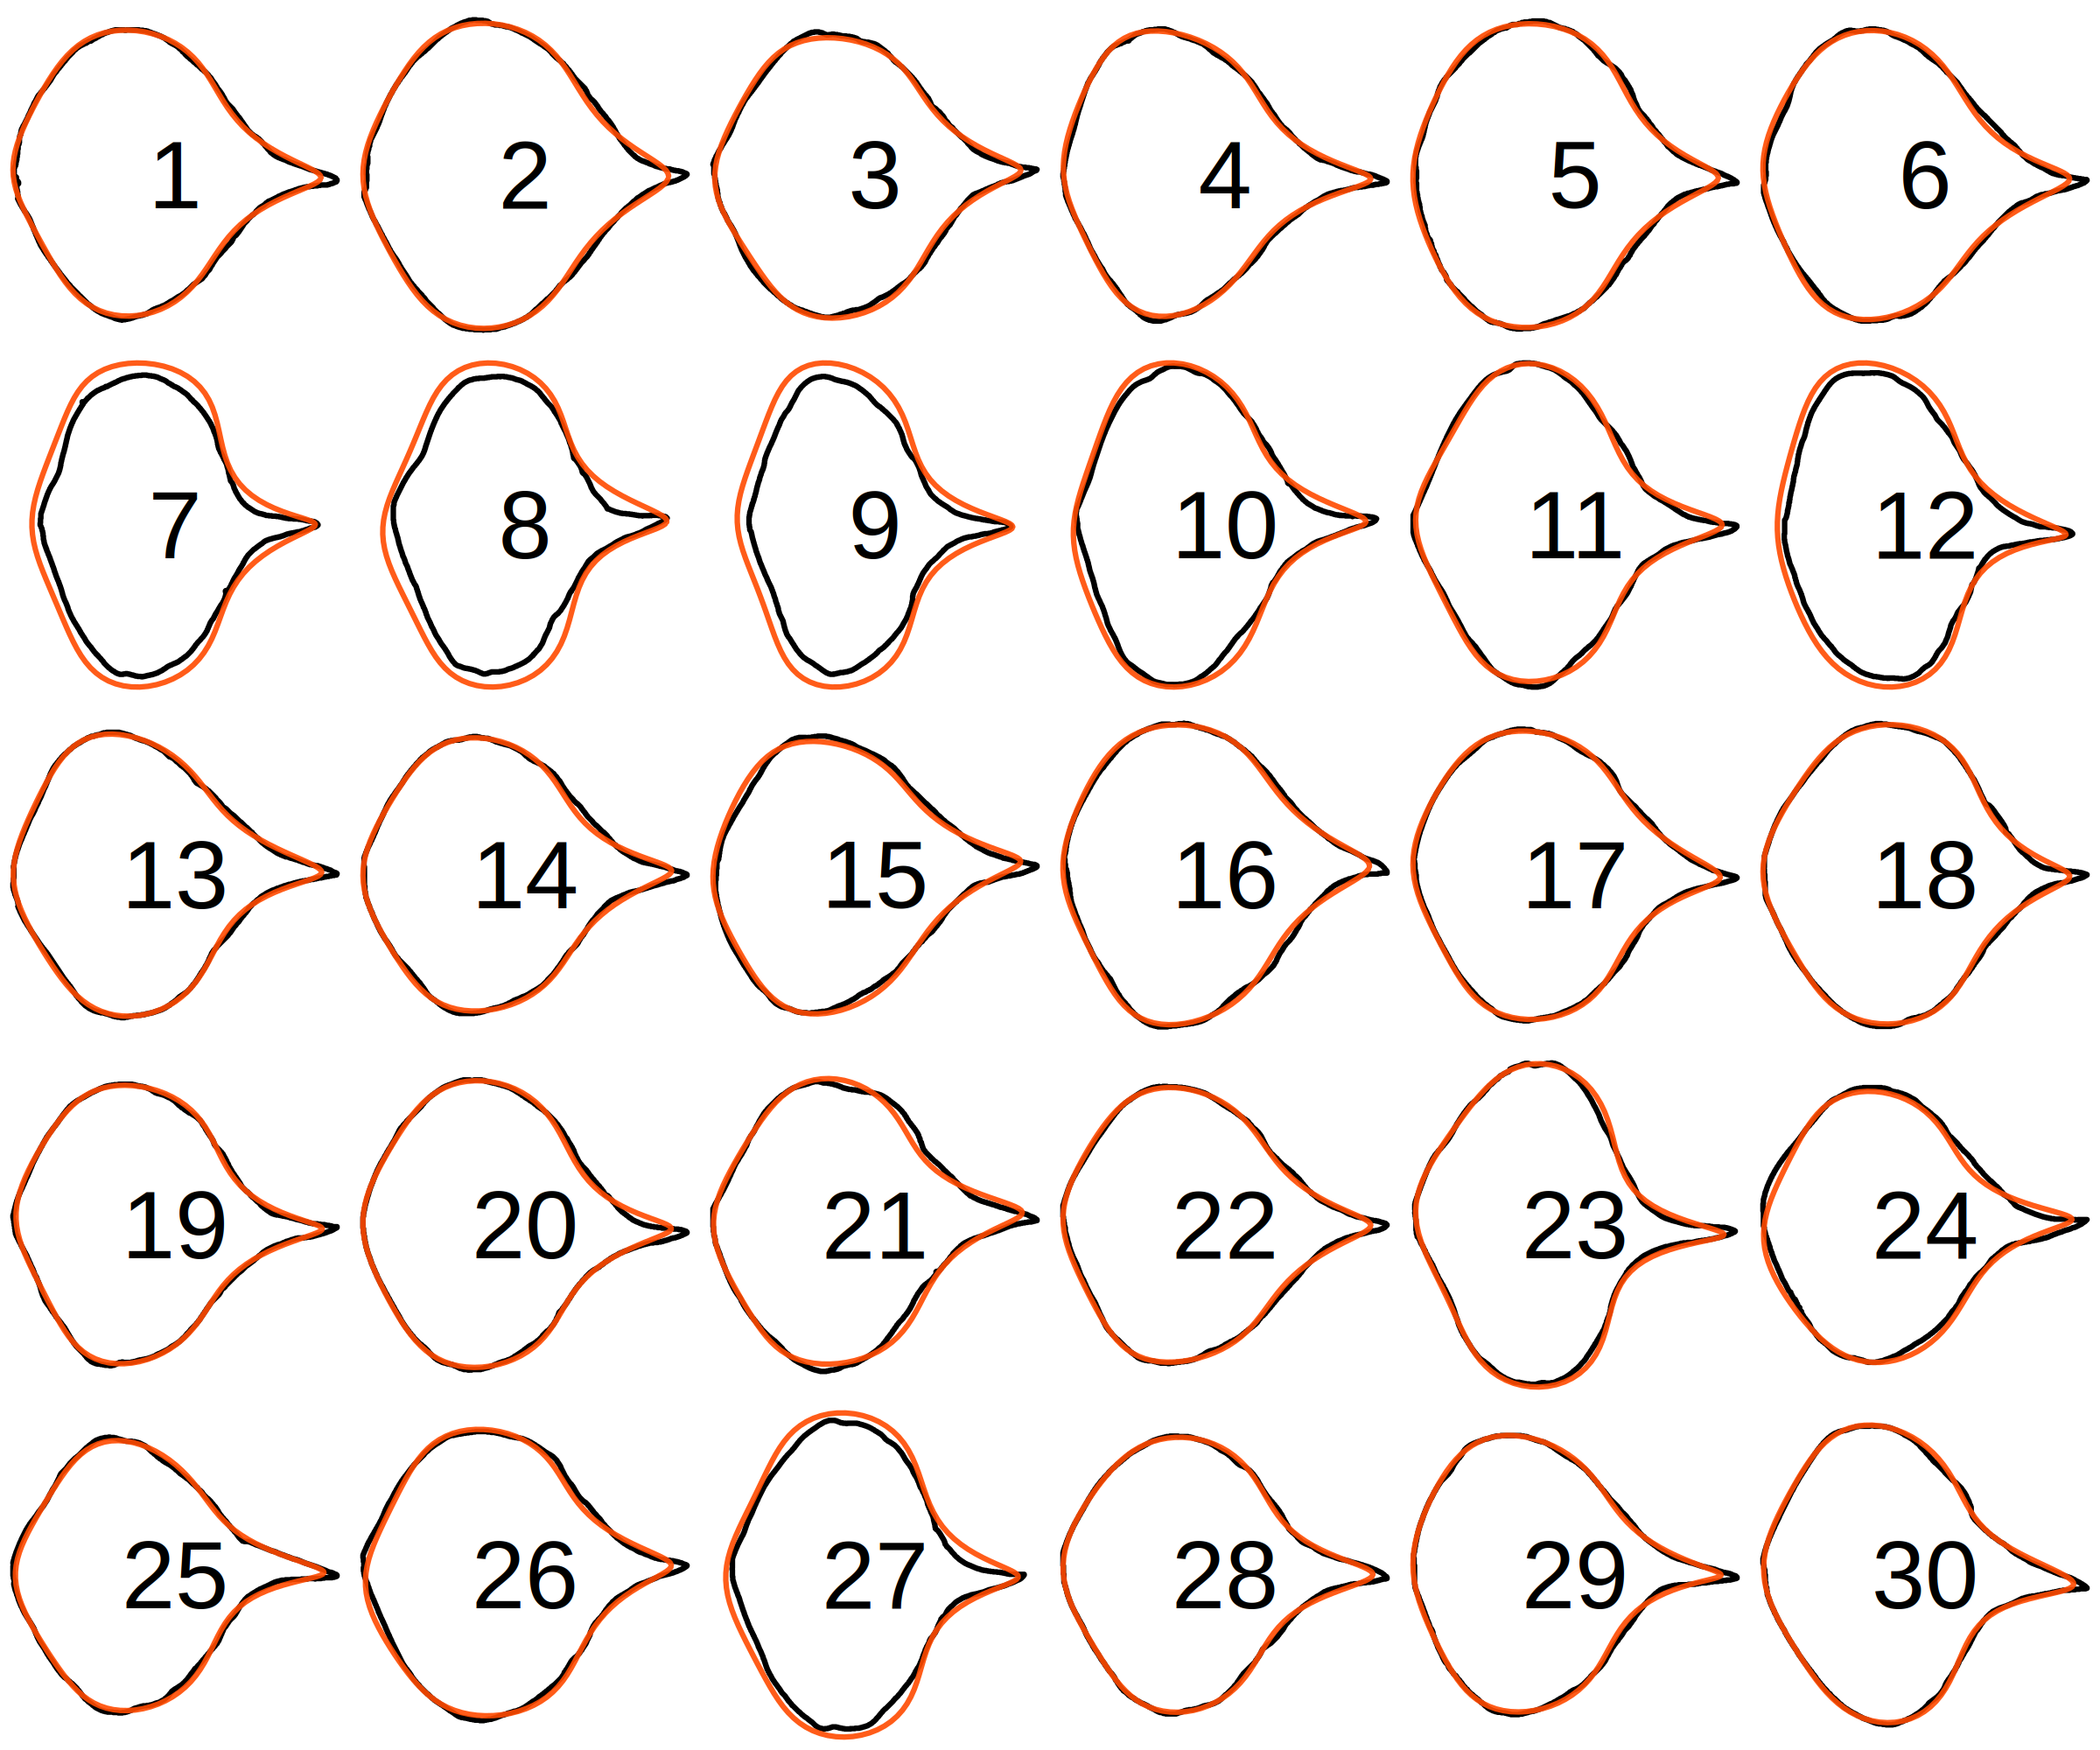

In [ ]:
r = subprocess.run(["Rscript", "/content/leaf/R/compare.R"],
                   capture_output=True, text=True, timeout=900)
print(r.stdout[-2000:]); print(r.stderr[-2000:])
assert r.returncode == 0, "compare.R failed"

display(Image(filename="/content/out/compare_contours.png"))

### The three PCAs from the author's notebook / 著者ノートブックの 3 つの PCA

Mapping from the author's `pca_triadica_sebifera.qmd` (commit `94a9995`) to this notebook:

| Author code (verbatim) | This notebook | Change |
| --- | --- | --- |
| `efourier(out, nb.h=5, norm=TRUE, start=FALSE)` → `PCA` → `pca_plot()` | `pca_all.R` block 1 | PNG device + explicit `print()` (Rscript needs it; Quarto auto-prints) |
| `efourier_true_norm(out, nb_h=5, x_sy=TRUE, y_sy=TRUE, skip_rotation=FALSE)` | `pca_all.R` block 2 | same cosmetic changes |
| `efourier_true_norm(out, nb_h=5, x_sy=TRUE, y_sy=FALSE, skip_rotation=TRUE)` | `pca_all.R` block 3 | same cosmetic changes |

Contours from the LeafContourEFD GUI are already biologically oriented, so the third
analysis applies only the x-symmetry correction (`skip_rotation=TRUE`, `y_sy=FALSE`) —
as stated in the authors' notebook. PC1 variance shares are printed from `PCA$eig`
(Momocs stores variance proportions there). **日本語**: 著者のノートブックのコードを
そのまま `pca_all.R` に写し、SVG→PNG と明示的 `print()` だけの外観上の変更で実行します。
GUI 由来の輪郭は既に生物学的に方向付けられているため、3 つ目は x 対称性補正のみ適用します。

In [ ]:
%%writefile /content/leaf/R/pca_all.R
suppressPackageStartupMessages(library(Momocs))
source("/content/leaf/R/load_data.R")
source("/content/leaf/R/normalization.R")
source("/content/leaf/R/pca_plot.R")

nb_h <- 5  # Number of harmonics (author notebook value; sensitivity at nb_h=10 below)

out <- Out(xy_list)  # convert to Momocs Out object

# (1) Conventional normalization (Kuhl & Giardina 1982 via Momocs)  [author verbatim]
ef_norm <- efourier(out, nb.h = nb_h, norm = TRUE, start = FALSE)
pca_norm <- PCA(ef_norm, center = TRUE, scale. = FALSE)

# (2) True EFD normalization  [author verbatim]
ef_true_norm <- efourier_true_norm(out, nb_h = nb_h, x_sy = TRUE, y_sy = TRUE,
                                   skip_rotation = FALSE)
pca_true_norm <- PCA(ef_true_norm, center = TRUE, scale. = FALSE)

# (3) Oriented true EFD normalization (GUI contours are already oriented)  [author verbatim]
ef_true_norm_oriented <- efourier_true_norm(out, nb_h = nb_h, x_sy = TRUE, y_sy = FALSE,
                                            skip_rotation = TRUE)
pca_true_norm_oriented <- PCA(ef_true_norm_oriented, center = TRUE, scale. = FALSE)

tab <- data.frame(
  method = c("conventional", "true", "oriented_true"),
  PC1_percent = 100 * c(pca_norm$eig[1], pca_true_norm$eig[1], pca_true_norm_oriented$eig[1]),
  PC2_percent = 100 * c(pca_norm$eig[2], pca_true_norm$eig[2], pca_true_norm_oriented$eig[2])
)
write.csv(tab, "/content/out/pca_pc1_nbh5.csv", row.names = FALSE)
cat("PC1 shares at nb_h = 5:\n")
print(tab)

# Cosmetic-only adaptation: PNG devices instead of the authors' SVG, explicit print().
png("/content/out/pca_efd_normalized.png", width = 1600, height = 1300, res = 150)
print(pca_plot(pca_norm)); dev.off()
png("/content/out/pca_true_efd_normalized.png", width = 1600, height = 1300, res = 150)
print(pca_plot(pca_true_norm)); dev.off()
png("/content/out/pca_oriented_true_efd_normalized.png", width = 1600, height = 1300, res = 150)
print(pca_plot(pca_true_norm_oriented)); dev.off()
cat("saved 3 PCA PNGs\n")

Writing /content/leaf/R/pca_all.R


### Run the three PCAs / 3 つの PCA の実行

Runs all three author analyses at nb_h = 5, saves the three PCA PNGs, prints the PC1/PC2
variance shares, and writes `/content/out/pca_pc1_nbh5.csv`.
**日本語**: nb_h = 5 で 3 種類の PCA を実行し、PNG を保存、PC1/PC2 の分散シェアを表示、
CSV に保存します。

In [ ]:
r = subprocess.run(["Rscript", "/content/leaf/R/pca_all.R"],
                   capture_output=True, text=True, timeout=900)
print(r.stdout[-3000:]); print(r.stderr[-2000:])
assert r.returncode == 0, "pca_all.R failed"

triadica_sebifera_03_06 -0.013861383  0.0030630502
triadica_sebifera_04_01  0.057941600  0.0488209079
triadica_sebifera_04_02  0.035125168  0.0507125603
triadica_sebifera_04_03  0.049350700 -0.0494022057
triadica_sebifera_04_04  0.075676873  0.0043002960
triadica_sebifera_04_05 -0.090049181  0.0634485526
triadica_sebifera_04_06  0.101546947 -0.0064069696
triadica_sebifera_05_01  0.111637332 -0.0090654678
triadica_sebifera_05_02  0.036638045 -0.0693471461
triadica_sebifera_05_03 -0.137069499 -0.0031423139
triadica_sebifera_05_04  0.080455192  0.0245199392
triadica_sebifera_05_05  0.087109362  0.0207094643
triadica_sebifera_05_06  0.012545808  0.0596484815

$f
 [1] 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
Levels: 1

$colors_groups
[1] "black"

$colors_rows
 [1] "black" "black" "black" "black" "black" "black" "black" "black" "black"
[10] "black" "black" "black" "black" "black" "black" "black" "black" "black"
[19] "black" "black" "black" "black" "black" "black" "black" "

**PCA — conventional normalization** (authors' `fig4d`); PC1 share printed above.
**日本語**: 従来法（Kuhl & Giardina 1982, Momocs による正規化）の PCA。

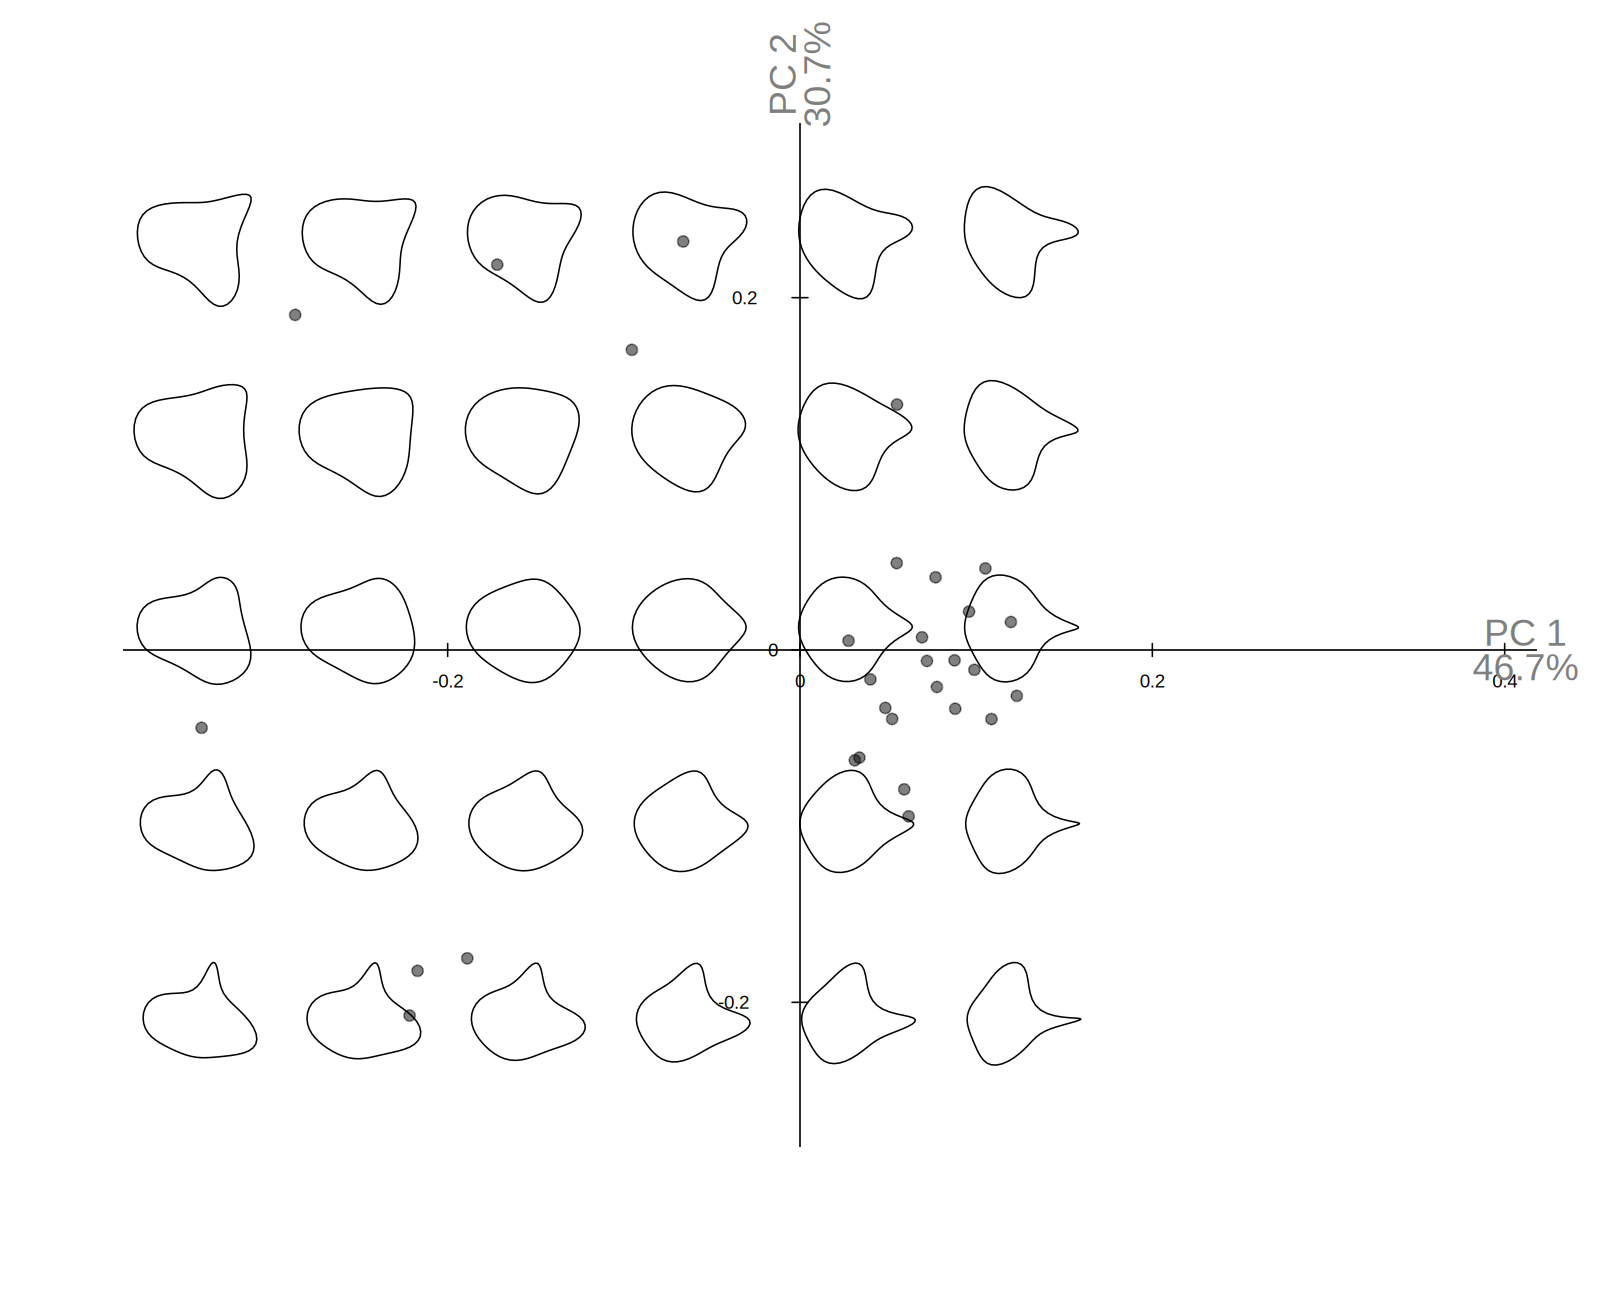

In [ ]:
from IPython.display import Image, display
display(Image(filename="/content/out/pca_efd_normalized.png"))

**PCA — true EFD normalization** (authors' `fig4e`).
**日本語**: true EFD 正規化（Wu et al. 2024 方式; `R/normalization.R` の `true_normalize_coe`）の PCA。

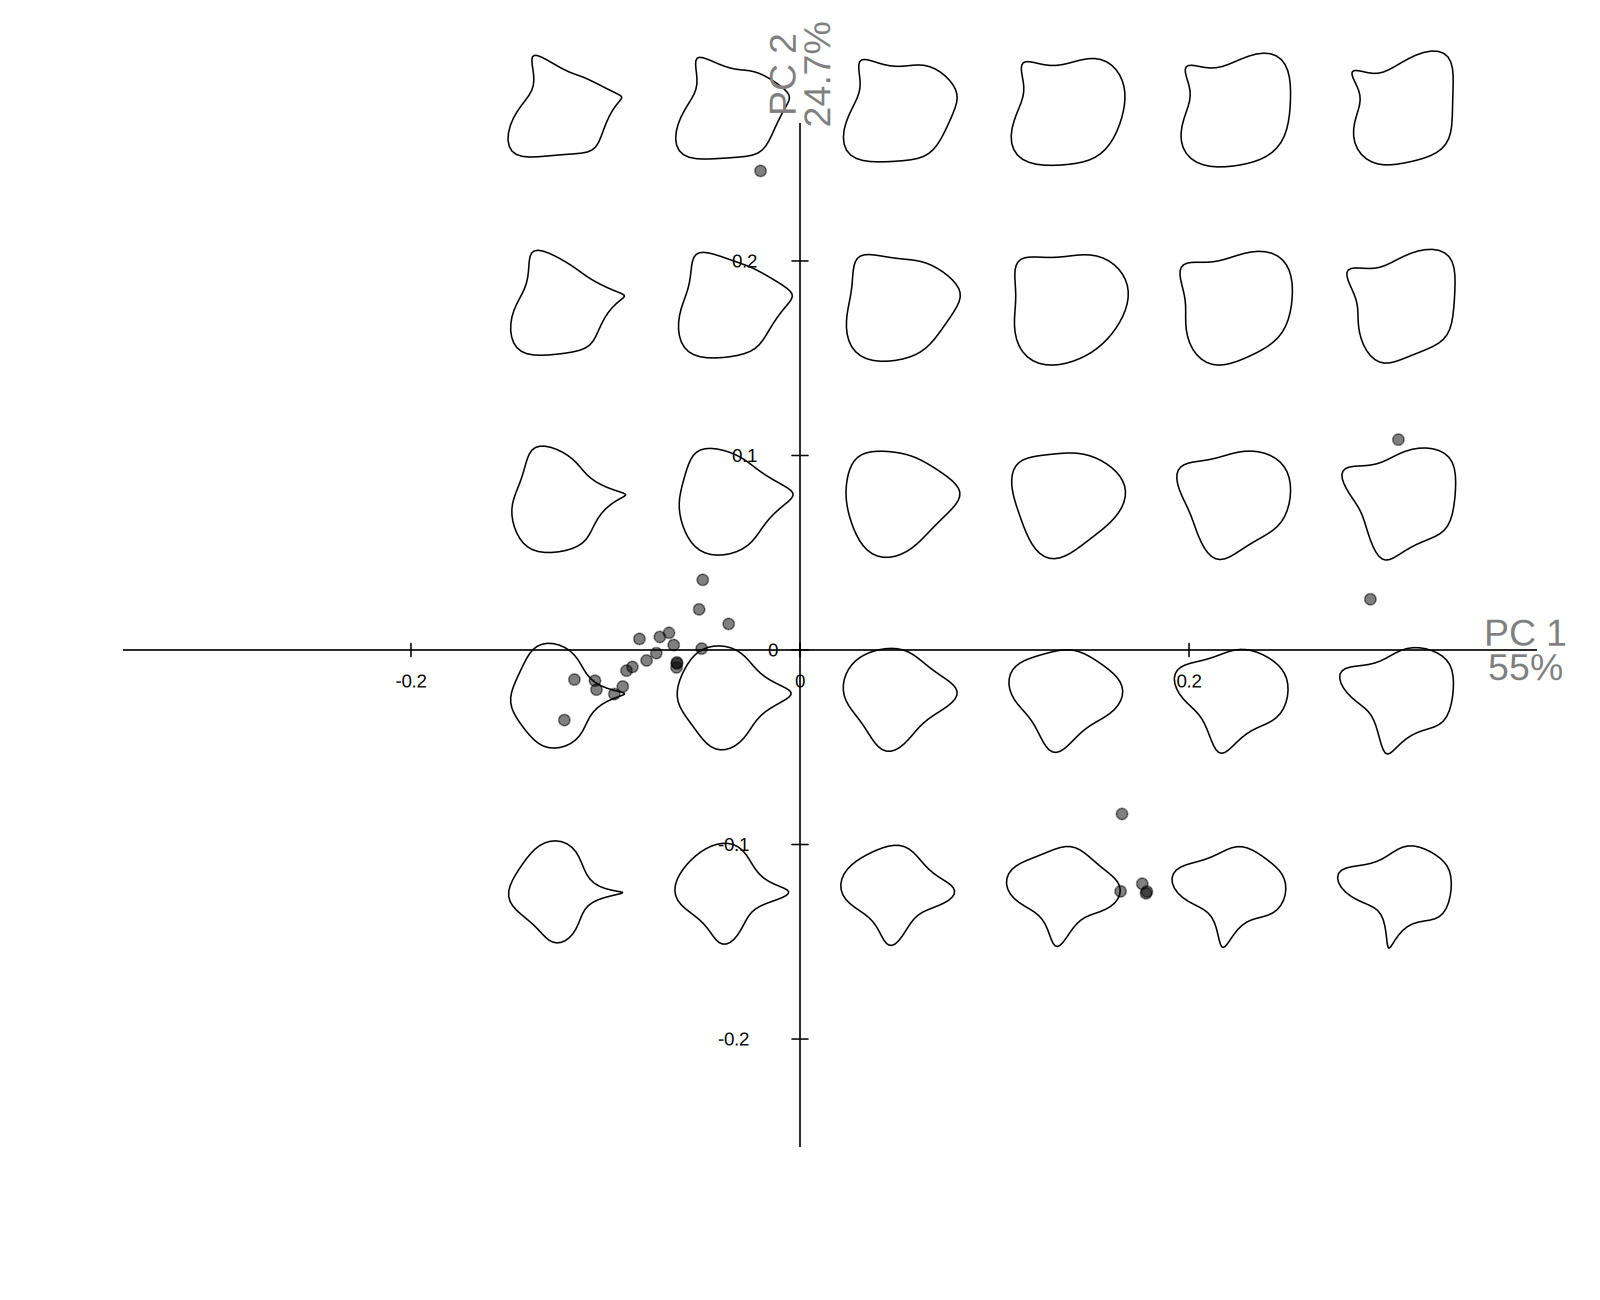

In [ ]:
from IPython.display import Image, display
display(Image(filename="/content/out/pca_true_efd_normalized.png"))

**PCA — oriented true EFD normalization** (authors' `fig4f`).
**日本語**: 方向付き true EFD 正規化（回転スキップ・x 対称性のみ）の PCA。

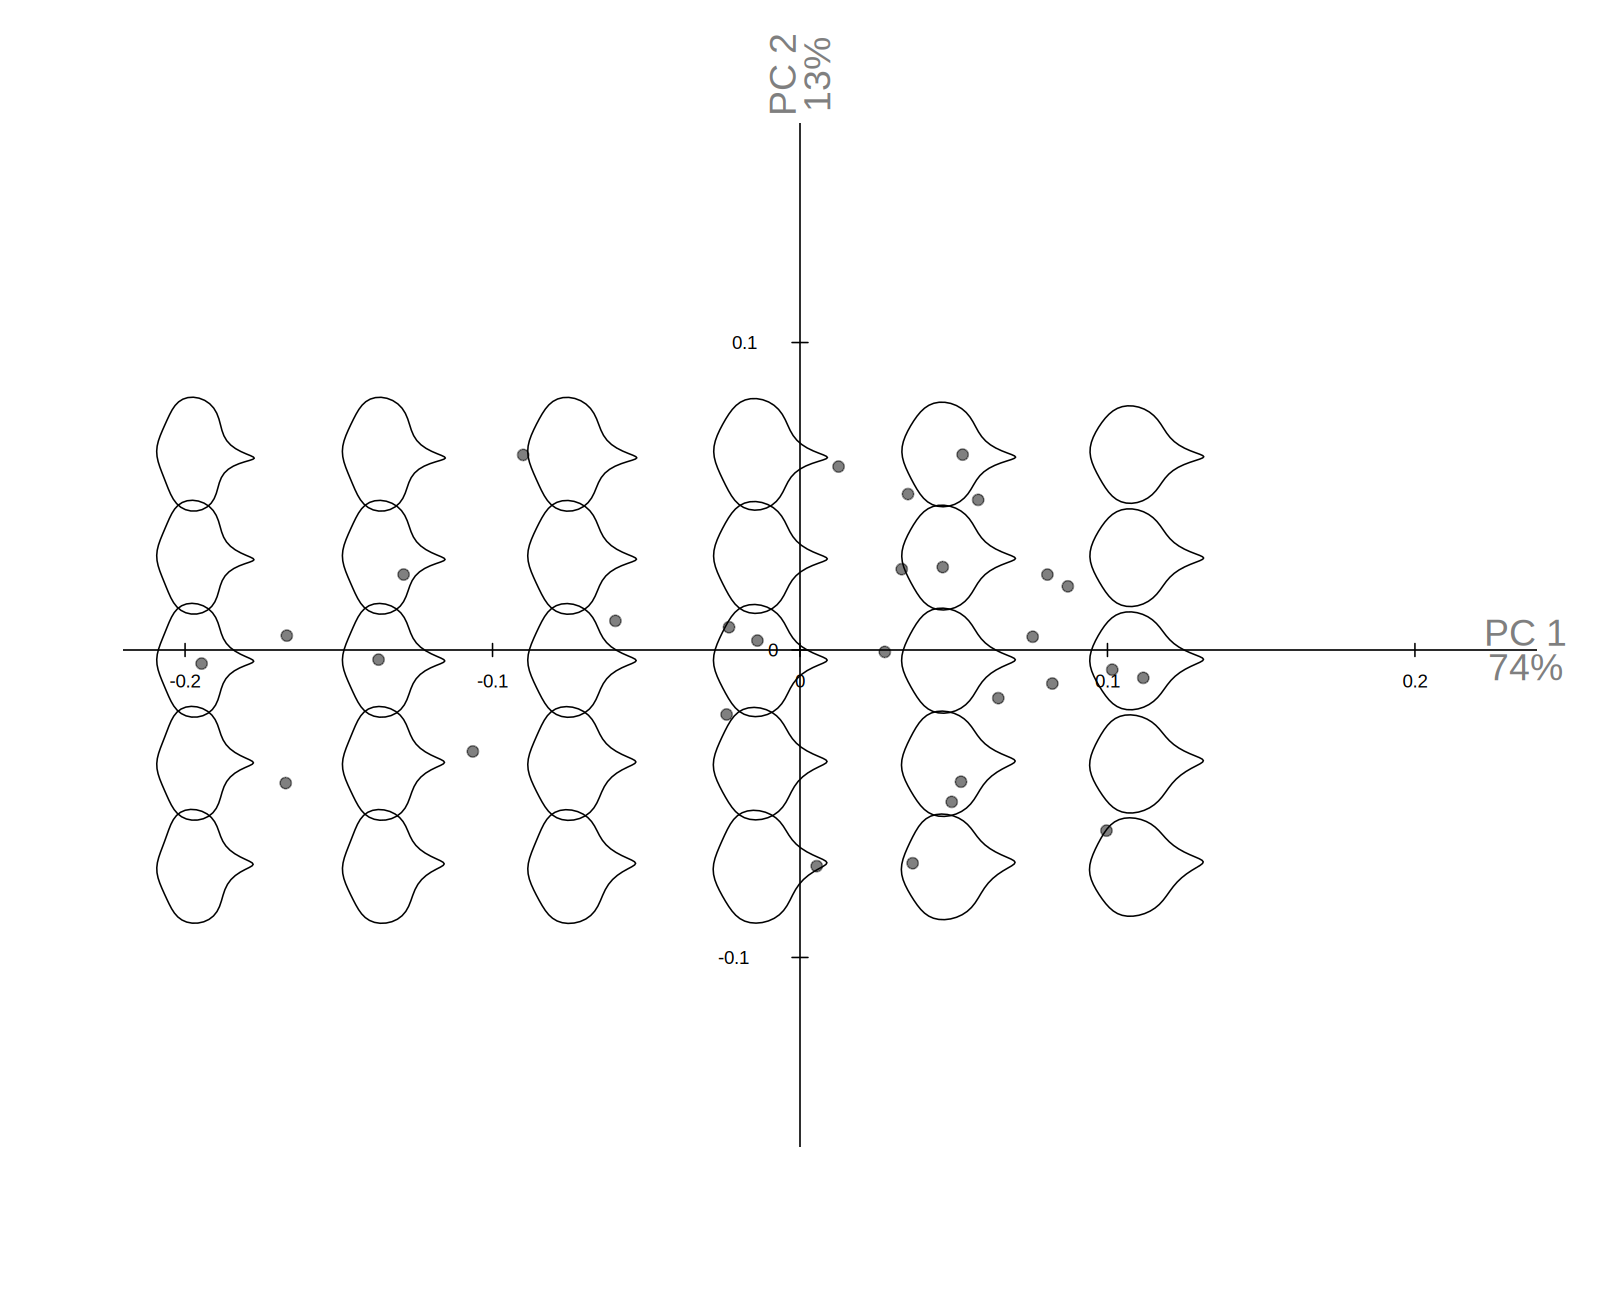

In [ ]:
from IPython.display import Image, display
display(Image(filename="/content/out/pca_oriented_true_efd_normalized.png"))

### Sensitivity: nb_h = 5 vs 10 / 調和数の感度分析

The author notebook code uses `nb_h <- 5`, while the preprint text reports **10 harmonics**
for *T. sebifera* with PC1 ≈ **46.7 % (conventional) / 55.0 % (true) / 74.0 % (oriented true)**.
Rather than silently resolving the discrepancy, this cell recomputes all three PCAs at
nb_h = 10 and the next cells compare PC1 shares with the paper-reported values.
**日本語**: 著者コードは nb_h = 5、論文本文は 10 調和（PC1 ≈ 46.7 / 55.0 / 74.0 %）で
食い違いがあるため、nb_h = 10 で再計算して論文値と比較します（黙って解決しません）。

In [ ]:
%%writefile /content/leaf/R/sensitivity.R
suppressPackageStartupMessages(library(Momocs))
source("/content/leaf/R/load_data.R")
source("/content/leaf/R/normalization.R")

pc1_share <- function(nb_h, method) {
  out <- Out(xy_list)
  ef <- switch(method,
    conventional = efourier(out, nb.h = nb_h, norm = TRUE, start = FALSE),
    true = efourier_true_norm(out, nb_h = nb_h, x_sy = TRUE, y_sy = TRUE,
                              skip_rotation = FALSE),
    oriented_true = efourier_true_norm(out, nb_h = nb_h, x_sy = TRUE, y_sy = FALSE,
                                       skip_rotation = TRUE)
  )
  pca <- PCA(ef, center = TRUE, scale. = FALSE)
  100 * pca$eig[1]
}

grid <- expand.grid(nb_h = c(5, 10),
                    method = c("conventional", "true", "oriented_true"),
                    stringsAsFactors = FALSE)
grid$PC1_percent <- mapply(function(n, m) pc1_share(n, m), grid$nb_h, grid$method)
write.csv(grid, "/content/out/nb_h_sensitivity.csv", row.names = FALSE)
print(grid[order(grid$method, grid$nb_h), ], row.names = FALSE)

Writing /content/leaf/R/sensitivity.R


### Run the sensitivity analysis / 感度分析の実行

Runs all three methods at nb_h = 5 and 10 and writes
`/content/out/nb_h_sensitivity.csv`. **日本語**: nb_h = 5 と 10 の両方で 3 手法を再計算し、
結果を CSV に保存します。

In [ ]:
r = subprocess.run(["Rscript", "/content/leaf/R/sensitivity.R"],
                   capture_output=True, text=True, timeout=900)
print(r.stdout[-3000:]); print(r.stderr[-2000:])
assert r.returncode == 0, "sensitivity.R failed"

loaded contours: 30 
 nb_h        method PC1_percent
    5  conventional    46.65084
   10  conventional    46.20509
    5 oriented_true    74.03271
   10 oriented_true    73.20601
    5          true    55.01595
   10          true    54.67090




### Compare with the paper-reported PC1 shares / 論文報告値との比較

Adds the preprint-reported PC1 values (10 harmonics) next to the measured ones. A
post-execution Markdown note at the end of this notebook states the observed agreement
or difference — nothing is hardcoded here. **日本語**: 実測の PC1 シェアに、論文報告値
（10 調和時）を並べて表示します。一致・不一致はノートブック末尾の説明に実測に基づいて記載します。

In [ ]:
import pandas as pd

df = pd.read_csv("/content/out/nb_h_sensitivity.csv")
paper = {"conventional": 46.7, "true": 55.0, "oriented_true": 74.0}
df["paper_PC1_percent_at_nb_h_10"] = df["method"].map(paper).where(df["nb_h"] == 10)
print(df[["method", "nb_h", "PC1_percent", "paper_PC1_percent_at_nb_h_10"]]
      .sort_values(["method", "nb_h"]).to_string(index=False))
df.to_csv("/content/out/nb_h_sensitivity_with_paper.csv", index=False)

       method  nb_h  PC1_percent  paper_PC1_percent_at_nb_h_10
 conventional     5    46.650841                           NaN
 conventional    10    46.205087                          46.7
oriented_true     5    74.032712                           NaN
oriented_true    10    73.206011                          74.0
         true     5    55.015950                           NaN
         true    10    54.670902                          55.0


## Interpretation & limitations / 解釈と限界

- **Scope**: this is a *partial* demonstration — the *T. sebifera* PCA comparison, the
  contour-check figure, and the nb_h sensitivity. It is **not** a verification of the
  paper's dataset-level conclusions, the GUI itself, or the other species analyses
  (`pca_quercus`, `direction_check`).
- The comparison figure validates that the author-published normalized coefficients
  reconstruct the original contours (a reference-annotation style check), not a new
  prediction.
- **nb_h discrepancy** (author code 5 vs preprint text 10) is documented and measured,
  not resolved; compare the printed PC1 shares with the paper values above.
- Author code provenance: [maple60/leaf-contour-efd-analysis](https://github.com/maple60/leaf-contour-efd-analysis)
  @ `94a9995` (`R/normalization.R`, `R/geometry.R`, `R/compare_contours.R`, `R/pca_plot.R`),
  mirrored as Zenodo record 19490591 v1.0.0 (CC-BY-4.0); data: Dryad
  doi:10.5061/dryad.6t1g1jxdh version 438792 (CC0). Momocs: Bonhomme et al. (2014),
  J. Stat. Software 56(13), v1.5.0 from the CRAN Archive.
- **参考文献** / references: the preprint (DOI 10.64898/2026.04.16.718881); Kuhl & Giardina
  (1982) for conventional EFD; Wu et al. (2024) style true normalization implemented in
  the authors' `R/normalization.R`.